Using device: cpu
--- Running Width Experiments ---
Width 1 (16-32-64)       | Channels: [16, 32, 64]       | Params:   24,234 | Train Loss: 1.4508 | Val Acc: 47.35%
Width 2 (32-64-128)      | Channels: [32, 64, 128]      | Params:   94,538 | Train Loss: 1.3041 | Val Acc: 55.42%
Width 3 (64-128-256)     | Channels: [64, 128, 256]     | Params:  373,386 | Train Loss: 1.1083 | Val Acc: 58.54%

--- Running Depth Experiments ---
Depth 1 (2 Layers)       | Channels: [32, 64]           | Params:   20,042 | Train Loss: 1.5487 | Val Acc: 45.46%
Depth 2 (3 Layers)       | Channels: [32, 64, 128]      | Params:   94,538 | Train Loss: 1.3041 | Val Acc: 55.42%
Depth 3 (4 Layers)       | Channels: [32, 64, 128, 256] | Params:  390,986 | Train Loss: 1.1050 | Val Acc: 60.98%


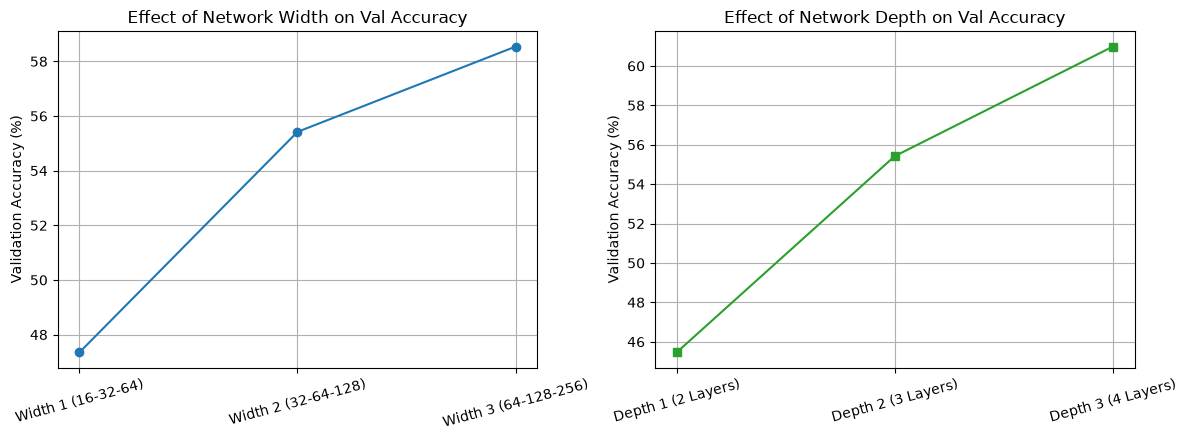

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "2"

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
train_ds, val_ds = random_split(full_train, [40000, 10000], generator=torch.Generator().manual_seed(42))

batch_size = 256
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

def build_cnn(channels):
  layers = []
  in_ch = 3
  for idx, out_ch in enumerate(channels):
    layers.append(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1))
    layers.append(nn.ReLU())
    if idx < 2:
      layers.append(nn.MaxPool2d(2, 2))
    in_ch = out_ch
  layers.append(nn.AdaptiveAvgPool2d((1, 1)))
  layers.append(nn.Flatten())
  layers.append(nn.Linear(in_ch, 10))
  return nn.Sequential(*layers)

def train_and_eval(label, channels, epochs=6):
  torch.manual_seed(42)
  tr_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
  model = build_cnn(channels).to(device)
  params = sum(p.numel() for p in model.parameters() if p.requires_grad)
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.Adam(model.parameters(), lr=1e-3)

  final_tr_loss = 0.0
  for ep in range(1, epochs + 1):
    model.train()
    tr_loss, tr_n = 0.0, 0
    for x, y in tr_loader:
      x, y = x.to(device), y.to(device)
      optimizer.zero_grad()
      out = model(x)
      loss = criterion(out, y)
      loss.backward()
      optimizer.step()
      tr_loss += float(loss.item()) * x.size(0)
      tr_n += int(y.size(0))
    final_tr_loss = tr_loss / tr_n

  model.eval()
  va_ok, va_n = 0, 0
  with torch.no_grad():
    for x, y in val_loader:
      x, y = x.to(device), y.to(device)
      va_ok += int((model(x).argmax(1) == y).sum().item())
      va_n += int(y.size(0))
  val_acc = 100.0 * va_ok / va_n
  print(f"{label:24s} | Channels: {str(channels):18s} | Params: {params:8,d} | Train Loss: {final_tr_loss:.4f} | Val Acc: {val_acc:.2f}%")
  return {"label": label, "channels": channels, "params": params, "train_loss": final_tr_loss, "val_acc": val_acc}

epochs = 6
width_configs = [
    ("Width 1 (16-32-64)", [16, 32, 64]),
    ("Width 2 (32-64-128)", [32, 64, 128]),
    ("Width 3 (64-128-256)", [64, 128, 256]),
]

depth_configs = [
    ("Depth 1 (2 Layers)", [32, 64]),
    ("Depth 2 (3 Layers)", [32, 64, 128]),
    ("Depth 3 (4 Layers)", [32, 64, 128, 256]),
]

print("--- Running Width Experiments ---")
width_res = [train_and_eval(lbl, ch, epochs=epochs) for lbl, ch in width_configs]

print("\n--- Running Depth Experiments ---")
depth_res = [train_and_eval(lbl, ch, epochs=epochs) for lbl, ch in depth_configs]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot([r["label"] for r in width_res], [r["val_acc"] for r in width_res], marker="o", color="tab:blue")
axes[0].set_title("Effect of Network Width on Val Accuracy")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(True)

axes[1].plot([r["label"] for r in depth_res], [r["val_acc"] for r in depth_res], marker="s", color="tab:green")
axes[1].set_title("Effect of Network Depth on Val Accuracy")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(True)

plt.tight_layout()
plt.savefig("exercise4_width_depth.png", dpi=150)
plt.show()